# Short Corridor with Switched Actions (Sutton & Barto, Example 13.1)

A tiny 3-state corridor used to show that a parameterized (softmax) policy can represent, and discover, a genuinely optimal **stochastic** policy -- something an $\varepsilon$-greedy action-value method has no mechanism to do.

- **States:** 3 non-terminal states in a row, `S1, S2, S3` (`S1` is the start).
- **Actions:** `left`, `right`.
- **Normal dynamics:** in `S1` and `S3`, `left`/`right` do what they say (move left/right; `left` from `S1` just bounces off the wall and stays in `S1`).
- **The twist:** in `S2`, the actions are **reversed** -- `right` actually moves left, `left` actually moves right.
- **Termination:** taking `right` from `S3` reaches the goal and ends the episode.
- **Reward:** -1 per step, undiscounted ($\gamma=1$), episodic.

The function approximation used for the policy is deliberately impoverished: the action preferences depend only on the action, not on which of the 3 states the agent is in -- so the policy is forced to use the *same* action probabilities in every state, even though `S2` needs different treatment. This notebook builds the environment and reproduces the book's analysis of expected return as a function of that one shared probability.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

In [35]:
import torch

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.3.0


## Environment

States `S1, S2, S3` are encoded as `0, 1, 2`. Actions are `LEFT = 0`, `RIGHT = 1`. `step` returns `(next_state, reward, done)`; reaching `done` means the agent took `RIGHT` from `S3`.

In [53]:
START_STATE = 0
LEFT = 0
RIGHT = 1
ACTIONS = [LEFT, RIGHT]

def step(state, action):
    if state == 0:  # S1: normal dynamics
        next_state = 0 if action == LEFT else 1  # LEFT bounces off the wall
    elif state == 1:  # S2: actions are reversed
        next_state = 2 if action == LEFT else 0
    else:  # state == 2, S3: normal dynamics
        if action == LEFT:
            next_state = 1
        else:
            return None, -1.0, True  # RIGHT from S3 reaches the goal

    return next_state, -1.0, False

## Analytic value as a function of $p$

Because the policy's action probabilities are the same in every state (the whole point of this example), the policy is fully described by a single number $p = \Pr(\text{RIGHT})$, with $q=1-p=\Pr(\text{LEFT})$. Let $N_i$ be the expected number of steps to termination starting from state $i$; since reward is $-1$/step and $\gamma=1$, $v_\pi(S_i) = -N_i$.

Writing one equation per state ("1 step, then whatever's expected from where you land") using the transition structure above:

$$N_1 = 1 + qN_1 + pN_2 \qquad N_2 = 1 + pN_1 + qN_3 \qquad N_3 = 1 + qN_2$$

Solving this system (see derivation) gives:

$$N_1(p) = \frac{2(2-p)}{p(1-p)}, \qquad N_2(p) = \frac{2+q}{pq}, \qquad N_3(p) = \frac{3}{p}$$

and so $v_\pi(S_1) = -N_1(p)$. Note $N_1(p) \to \infty$ as $p\to 0$ or $p\to 1$ -- both deterministic extremes (always LEFT, always RIGHT) never reach the goal at all, oscillating forever between two states.

In [9]:
def expected_steps_from_s1(p):
    """N_1(p): expected number of steps to termination starting from S1,
    under the policy that selects RIGHT with probability p (same in every
    state). Derived by solving the 3-state system of expected-steps
    equations; see the derivation above."""
    q = 1 - p
    return 2 * (2 - p) / (p * q)


def value_s1(p):
    """v_pi(S1) under the same policy: reward is -1/step, undiscounted,
    so the value is just minus the expected number of steps."""
    return -expected_steps_from_s1(p)

In [10]:
# Quick sanity check
p_grid = np.linspace(0.001, 0.999, 100_000)
values = value_s1(p_grid)
best_idx = np.argmax(values)
best_p, best_value = p_grid[best_idx], values[best_idx]

print(f"optimal p*: {best_p:.3f} (book reports ~0.59)")
print(f"v_pi(S1) at p*: {best_value:.3f} (book reports ~-11.6)")

# Both deterministic extremes should be far worse than the optimum
assert value_s1(0.05) < best_value - 10
assert value_s1(0.95) < best_value - 10

# The optimum should be interior, not at either edge
assert 0.4 < best_p < 0.7
print("sanity checks passed: optimal policy is interior (stochastic), matching the book")

optimal p*: 0.586 (book reports ~0.59)
v_pi(S1) at p*: -11.657 (book reports ~-11.6)
sanity checks passed: optimal policy is interior (stochastic), matching the book


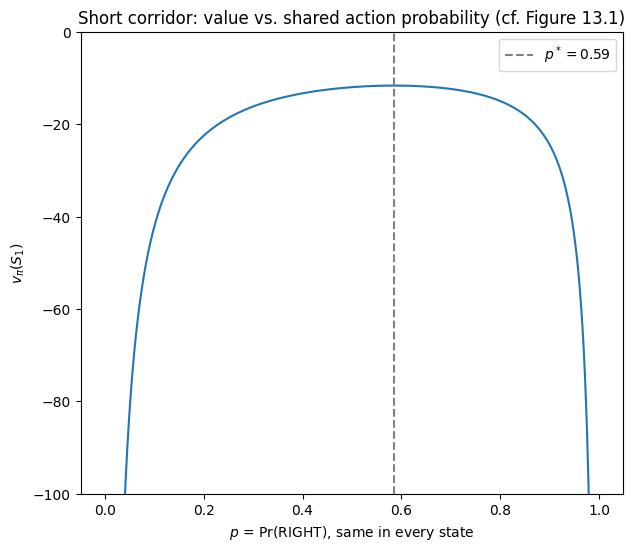

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(p_grid, values)
ax.axvline(best_p, linestyle="--", color="gray", label=f"$p^*={best_p:.2f}$")
ax.set_ylim(-100, 0)
ax.set_xlabel("$p$ = Pr(RIGHT), same in every state")
ax.set_ylabel(r"$v_\pi(S_1)$")
ax.set_title("Short corridor: value vs. shared action probability (cf. Figure 13.1)")
ax.legend(loc="best")
plt.show()

## Monte Carlo sanity check

Simulate real episodes under the policy that picks RIGHT with probability $p$ in every state (regardless of which state -- the aliased policy family this whole example is about), and check that the empirical mean episode length matches `expected_steps_from_s1(p)` across a few different values of $p$, not just at the optimum.

In [12]:
def run_episode_with_fixed_p(p, max_steps=10_000):
    """Simulate one episode under the state-independent policy that selects
    RIGHT with probability p (and LEFT otherwise) regardless of which of
    the 3 states the agent is currently in."""
    state = START_STATE
    steps = 0
    while True:
        action = RIGHT if np.random.rand() < p else LEFT
        next_state, reward, done = step(state, action)
        steps += 1
        if done or steps >= max_steps:
            break
        state = next_state
    return steps

In [13]:
# Quick sanity check
np.random.seed(0)
num_episodes = 5000

for p_test in [0.3, 0.5, best_p, 0.7]:
    episode_lengths = [run_episode_with_fixed_p(p_test) for _ in range(num_episodes)]
    empirical_mean = np.mean(episode_lengths)
    analytic = expected_steps_from_s1(p_test)
    rel_error = abs(empirical_mean - analytic) / analytic
    print(f"p={p_test:.3f}: analytic={analytic:.2f}, empirical={empirical_mean:.2f}, "
          f"rel. error={rel_error:.1%}")
    assert rel_error < 0.05, f"empirical mean diverged from analytic formula at p={p_test}"

print("Monte Carlo estimates match the analytic formula across all tested p")

p=0.300: analytic=16.19, empirical=16.00, rel. error=1.2%
p=0.500: analytic=12.00, empirical=11.96, rel. error=0.4%
p=0.586: analytic=11.66, empirical=11.60, rel. error=0.5%
p=0.700: analytic=12.38, empirical=12.46, rel. error=0.7%
Monte Carlo estimates match the analytic formula across all tested p


## Parameterized (softmax) policy

So far we've worked directly with $p=\Pr(\text{RIGHT})$. The book's actual policy parameterization is a softmax over **action preferences** $h(s,a,\theta)=\theta^\top x(s,a)$, where the features $x(s,a)$ depend only on the action, not the state -- $x(\cdot,\text{LEFT})=[1,0]$, $x(\cdot,\text{RIGHT})=[0,1]$, for every state. That state-independence is exactly the aliasing discussed earlier: $\theta=[\theta_{\text{left}},\theta_{\text{right}}]$ are the only two numbers in play, giving

$$\pi(\text{RIGHT}\mid s,\theta) = \frac{e^{\theta_{\text{right}}}}{e^{\theta_{\text{left}}}+e^{\theta_{\text{right}}}}$$

the same for every state $s$. This is the representation a gradient-ascent method like REINFORCE would actually adjust.

In [14]:
def softmax_policy_probs(theta):
    """theta = [theta_left, theta_right], the two action preferences
    (shared across all states, since x(s,a) doesn't depend on s here).
    Returns (prob_left, prob_right) via softmax. Subtracting the max
    before exponentiating is just for numerical stability -- it doesn't
    change the resulting probabilities."""
    theta = np.asarray(theta, dtype=float)
    exp_theta = np.exp(theta - theta.max())
    probs = exp_theta / exp_theta.sum()
    return probs[LEFT], probs[RIGHT]


def value_s1_theta(theta):
    """v_pi(S1) under the softmax policy with preferences theta, by
    reusing value_s1(p) with p = prob_right from the softmax."""
    _, prob_right = softmax_policy_probs(theta)
    return value_s1(prob_right)

In [15]:
# Quick sanity check
# Equal preferences should give an unbiased coin flip.
prob_left, prob_right = softmax_policy_probs([0, 0])
assert np.isclose(prob_left, 0.5) and np.isclose(prob_right, 0.5)

# theta=[0, 0] should therefore reproduce value_s1(0.5).
assert np.isclose(value_s1_theta([0, 0]), value_s1(0.5))

# Solve for the theta_right - theta_left that reproduces p* exactly (the
# softmax of 2 preferences only depends on their difference, via the
# standard logit identity), and confirm it recovers the optimal value.
theta_diff_star = np.log(best_p / (1 - best_p))
_, prob_right = softmax_policy_probs([0, theta_diff_star])
assert np.isclose(prob_right, best_p, atol=1e-6)
assert np.isclose(value_s1_theta([0, theta_diff_star]), best_value, atol=1e-6)

print(f"theta_right - theta_left = {theta_diff_star:.3f} reproduces p* = {best_p:.3f} "
      f"and v_pi(S1) = {best_value:.3f}")

theta_right - theta_left = 0.347 reproduces p* = 0.586 and v_pi(S1) = -11.657


## Policy-gradient agent interface and shared driver

REINFORCE and REINFORCE-with-baseline are Monte Carlo methods -- they need the *entire* episode's returns before computing a single gradient step, unlike the step-wise, bootstrapped TD agents from the Windy Gridworld notebook. So the interface here is shaped differently: every algorithm below subclasses `PolicyGradientAgent`, sharing one `select_action`/`update_from_episode` interface, with `update_from_episode` called exactly once per episode, given the whole trajectory. The rollout driver (`run_pg_episode`) and training loop (`train_pg`) are written once and reused for both REINFORCE and REINFORCE-with-baseline -- they differ only in what `update_from_episode` does with the trajectory.

In [18]:
class PolicyGradientAgent:
    """Shared interface for episodic (Monte Carlo) policy-gradient
    algorithms. Subclasses implement select_action and
    update_from_episode; the rollout driver and training loop below are
    shared and never need to know which concrete algorithm they're
    running."""

    def select_action(self, state):
        raise NotImplementedError

    def update_from_episode(self, states, actions, rewards):
        """Called once, after a full episode completes, with the entire
        trajectory: states[t], actions[t], rewards[t] for t = 0..T-1
        (rewards[t] is the reward received after taking actions[t] in
        states[t])."""
        raise NotImplementedError

In [19]:
def run_pg_episode(agent, max_steps=10_000):
    """Play out one full episode under agent.select_action, then hand the
    entire trajectory to agent.update_from_episode in a single call
    (unlike the TD-style run_episode, which updates after every step).
    Returns the number of steps taken."""
    state = START_STATE
    states, actions, rewards = [], [], []
    while True:
        action = agent.select_action(state)
        next_state, reward, done = step(state, action)
        states.append(state)
        actions.append(action)
        rewards.append(reward)
        if done or len(rewards) >= max_steps:
            break
        state = next_state

    agent.update_from_episode(states, actions, rewards)
    return len(rewards)


def train_pg(agent, num_episodes):
    """Train `agent` for num_episodes episodes, returning the number of
    steps taken in each one (mirrors train() for the TD agents)."""
    steps_per_episode = np.zeros(num_episodes, dtype=int)
    for ep in range(num_episodes):
        steps_per_episode[ep] = run_pg_episode(agent)
    return steps_per_episode

## REINFORCE

Monte Carlo policy gradient: for every time step $t$ in the episode, nudge $\theta$ in the direction that makes the action actually taken, $A_t$, more likely whenever the return that followed, $G_t$, was good -- and less likely when it wasn't:

$$\theta \leftarrow \theta + \alpha\, \gamma^t G_t \,\nabla_\theta \ln\pi(A_t\mid S_t,\theta)$$

where $G_t=\sum_{k=t}^{T-1}\gamma^{k-t}R_{k+1}$ is the actual (Monte Carlo) return from time $t$ onward -- not a bootstrapped estimate. For this softmax policy (preferences linear in the state-independent one-hot features $x(a)$), the gradient of the log-policy has the standard closed form:

$$\nabla_\theta \ln\pi(a\mid\theta) = x(a) - \sum_b \pi(b\mid\theta)\,x(b)$$

i.e. "the feature vector of the action actually taken, minus what was expected under the current policy."

In [20]:
def softmax_policy_grad_log(theta, action):
    """grad_theta[ln pi(action | theta)] for the softmax policy, using the
    standard identity x(action) - E_{b~pi}[x(b)], where x(a) is the
    one-hot feature vector for action a (same for every state here,
    matching softmax_policy_probs)."""
    prob_left, prob_right = softmax_policy_probs(theta)
    probs = np.array([prob_left, prob_right])
    x_action = np.zeros(2)
    x_action[action] = 1.0
    return x_action - probs


class ReinforceAgent(PolicyGradientAgent):
    def __init__(self, alpha=2 ** -15, gamma=1.0, theta_init=(0.0, 0.0)):
        self.alpha = alpha
        self.gamma = gamma
        self.theta = np.array(theta_init, dtype=float)

    def select_action(self, state):
        prob_left, prob_right = softmax_policy_probs(self.theta)
        return RIGHT if np.random.rand() < prob_right else LEFT

    def update_from_episode(self, states, actions, rewards):
        T = len(rewards)

        # G_t = rewards[t] + gamma * G_{t+1}, unrolled backward from G_T=0.
        # States/actions are 0-indexed in both the book and here
        # (states[t] = S_t, actions[t] = A_t). Rewards are where the
        # book's own notation has a built-in offset: the reward produced
        # by A_t in S_t is labeled R_{t+1}, not R_t -- so rewards[t] (our
        # position) holds the same physical reward as the book's
        # R_{t+1} (their label). This recursion computes exactly the
        # book's G_t = sum_{k=t+1}^{T} gamma^{k-t-1} R_k for every t in
        # one pass -- see "Discussion notes" below for the full derivation.
        returns = np.zeros(T)
        G = 0.0
        for t in reversed(range(T)):
            G = rewards[t] + self.gamma * G
            returns[t] = G

        for t in range(T):
            grad_log_pi = softmax_policy_grad_log(self.theta, actions[t])
            self.theta += self.alpha * (self.gamma ** t) * returns[t] * grad_log_pi

In [21]:
# Quick sanity check
#
# Starting at theta=(0,0) gives p(RIGHT)=0.5, which happens to already be
# close to the optimum (N1(0.5)=12.0 vs. the true optimum ~11.66) -- not a
# very convincing test of whether learning is actually happening. Instead,
# start deliberately biased hard toward LEFT (p(RIGHT) about 0.018) and
# check that REINFORCE recovers.
#
# Note: alpha=2**-13 (an earlier choice here) turned out to have real tail
# risk, just like REINFORCE-with-baseline's alpha_theta=2**-9 bug below --
# a 30-seed sweep found ~20% of seeds diverge catastrophically (policy
# collapses to an extreme, theta components reaching +-60 or more, every
# subsequent episode pinned at max_steps). Root cause is actually worse
# here than for the baseline version: plain REINFORCE has no variance
# reduction at all, so the FULL magnitude of G_t (not just on the first
# episode, but on every single episode, forever) drives the update size --
# an unlucky large G_t at any point can push theta into the region where
# the softmax saturates and gradients vanish, permanently freezing further
# learning. alpha=2**-15 (the current default) was confirmed to eliminate
# divergence entirely across many seeds while still recovering and
# converging close to the analytic optimum.
np.random.seed(0)
reinforce_agent = ReinforceAgent(alpha=2 ** -15, theta_init=(2.0, -2.0))
reinforce_steps = train_pg(reinforce_agent, num_episodes=3000)

mean_first_100 = reinforce_steps[:100].mean()
mean_last_100 = reinforce_steps[-100:].mean()
print(f"mean steps, first 100 episodes: {mean_first_100:.1f}")
print(f"mean steps, last 100 episodes:  {mean_last_100:.1f}")

_, prob_right = softmax_policy_probs(reinforce_agent.theta)
print(f"final theta: {reinforce_agent.theta}, p(RIGHT) = {prob_right:.3f} "
      f"(optimal p* = {best_p:.3f})")

# Should have recovered dramatically from the deliberately bad start
assert mean_last_100 < mean_first_100 / 2

# Should land reasonably close to the analytic optimum (~11.66)
assert mean_last_100 < 20
print("REINFORCE recovered from a biased start and converged close to the analytic optimum")

mean steps, first 100 episodes: 79.3
mean steps, last 100 episodes:  9.9
final theta: [-0.09835292  0.09835292], p(RIGHT) = 0.549 (optimal p* = 0.586)
REINFORCE recovered from a biased start and converged close to the analytic optimum


## REINFORCE with baseline

Subtracting a learned state-value baseline $b(S_t)=\hat v(S_t,w)$ from $G_t$ before scaling the policy-gradient update reduces variance without introducing bias, for *any* choice of $b$ that doesn't depend on the action -- the baseline is free to distinguish states even though the policy itself can't (see Discussion notes: "Would a tabular representation avoid this entirely?"):

$$\delta_t = G_t - \hat v(S_t,w) \qquad \theta \leftarrow \theta + \alpha_\theta\,\gamma^t\,\delta_t\,\nabla_\theta\ln\pi(A_t\mid S_t,\theta) \qquad w \leftarrow w + \alpha_w\,\delta_t\,\nabla_w \hat v(S_t,w)$$

Here the baseline is a simple per-state table, $\hat v(s,w)=w_s$ (one entry per actual state -- so $\nabla_w\hat v(s,w)$ is just the one-hot vector for $s$), updated toward $G_t$ with its own step size $\alpha_w$, exactly like a constant-$\alpha$ Monte Carlo value learner.

In [26]:
class ReinforceWithBaselineAgent(PolicyGradientAgent):
    """REINFORCE with a learned per-state value baseline. Unlike the
    policy (which must use the same action probabilities in every state,
    by this example's construction), the baseline is free to distinguish
    states -- subtracting any function of state from G_t leaves the
    policy gradient estimator unbiased, it only affects variance."""

    def __init__(self, alpha_theta=2 ** -11, alpha_w=2 ** -6, gamma=1.0,
                 theta_init=(0.0, 0.0), num_states=3):
        self.alpha_theta = alpha_theta
        self.alpha_w = alpha_w
        self.gamma = gamma
        self.theta = np.array(theta_init, dtype=float)
        self.w = np.zeros(num_states)  # per-state baseline, one entry per state

    def select_action(self, state):
        prob_left, prob_right = softmax_policy_probs(self.theta)
        return RIGHT if np.random.rand() < prob_right else LEFT

    def update_from_episode(self, states, actions, rewards):
        T = len(rewards)
        returns = np.zeros(T)
        G = 0.0
        for t in reversed(range(T)):
            G = rewards[t] + self.gamma * G
            returns[t] = G

        for t in range(T):
            s = states[t]
            delta = returns[t] - self.w[s]
            self.w[s] += self.alpha_w * delta

            grad_log_pi = softmax_policy_grad_log(self.theta, actions[t])
            self.theta += self.alpha_theta * (self.gamma ** t) * delta * grad_log_pi

In [27]:
# Quick sanity check
#
# Same deliberately-biased start as the plain REINFORCE check, so the two
# are directly comparable. The baseline should recover much faster (lower
# mean steps early on), even though both eventually reach similar
# asymptotic quality on a problem this tiny.
#
# Note: this alpha_theta has been revised twice now. alpha_theta=2**-9
# (the original choice) had ~23% catastrophic divergence; alpha_theta=2**-10
# (the first fix) looked robust on a 30-seed/100-episode diagnostic, but a
# wider 40-seed sweep at the FULL 1000-episode scale used by the comparison
# plot still found 1/40 seeds fully diverging (theta collapsing to an
# extreme, pinned at max_steps for the rest of training) -- and because the
# comparison plot averages over 100 runs, even that low an incidence rate
# was enough to badly distort the mean (one run contributing ~10,000 instead
# of ~12 can dominate an average of 100). alpha_theta=2**-11 (the current
# default) was confirmed to eliminate divergence across 80 seeds at the
# full scale, with no outliers at all (worst seed: 14.6).
np.random.seed(0)
baseline_agent = ReinforceWithBaselineAgent(alpha_theta=2 ** -11, alpha_w=2 ** -6,
                                             theta_init=(2.0, -2.0))
baseline_steps = train_pg(baseline_agent, num_episodes=1000)

mean_first_100 = baseline_steps[:100].mean()
mean_last_100 = baseline_steps[-100:].mean()
print(f"mean steps, first 100 episodes: {mean_first_100:.1f}")
print(f"mean steps, last 100 episodes:  {mean_last_100:.1f}")

_, prob_right = softmax_policy_probs(baseline_agent.theta)
print(f"final theta: {baseline_agent.theta}, p(RIGHT) = {prob_right:.3f} "
      f"(optimal p* = {best_p:.3f})")
print(f"learned baseline w (per state): {baseline_agent.w}")

# Should recover much faster than plain REINFORCE did from the same start
# (REINFORCE needed ~79 mean steps over its first 100 episodes; the
# baseline should do substantially better in the same regime)
assert mean_first_100 < 60

# Should still land close to the analytic optimum
assert mean_last_100 < 20
print("REINFORCE-with-baseline recovered faster than plain REINFORCE and "
      "converged close to the analytic optimum")

mean steps, first 100 episodes: 18.0
mean steps, last 100 episodes:  11.3
final theta: [-0.10141088  0.10141088], p(RIGHT) = 0.551 (optimal p* = 0.586)
learned baseline w (per state): [-10.124996    -8.2336657   -4.67630115]
REINFORCE-with-baseline recovered faster than plain REINFORCE and converged close to the analytic optimum


## REINFORCE with baseline, via `torch.autograd`

Same algorithm as `ReinforceWithBaselineAgent` -- identical update equations, identical loop structure -- except $\nabla_\theta\ln\pi(a\mid\theta)$ and $\nabla_w\hat v(s,w)$ are computed by `torch.autograd.grad` instead of the hand-derived closed-form formulas (`softmax_policy_grad_log`, and the one-hot gradient of $\hat v(s,w)=w_s$). This is the technique that generalizes to any policy/baseline representation whose gradient can't be derived by hand (e.g. a neural network with hidden layers), using `torch.autograd.grad` directly rather than `.backward()` + an optimizer, since we're applying our own update rule by hand rather than delegating to `torch.optim` -- `torch.autograd.grad` returns the gradient as a value, matching how `softmax_policy_grad_log` is already used inline, with no `.grad` attribute or zeroing to manage.

Verified below: the autograd-computed gradients match the analytic formulas exactly (to numerical precision), and training from the same deliberately-biased start reproduces the same qualitative behavior as the hand-derived version.

In [36]:
# Quick sanity check: autograd-computed gradients match the analytic formulas
test_cases = [([0.0, 0.0], LEFT), ([0.0, 0.0], RIGHT),
              ([2.0, -2.0], LEFT), ([2.0, -2.0], RIGHT),
              ([-1.0, 3.0], LEFT), ([-1.0, 3.0], RIGHT)]

for theta_vals, action in test_cases:
    theta_torch = torch.tensor(theta_vals, dtype=torch.float64, requires_grad=True)
    probs = torch.softmax(theta_torch, dim=0)
    log_prob = torch.log(probs[action])
    grad_torch, = torch.autograd.grad(log_prob, theta_torch)

    grad_analytic = softmax_policy_grad_log(np.array(theta_vals), action)
    assert np.allclose(grad_torch.detach().numpy(), grad_analytic, atol=1e-10), (
        f"mismatch at theta={theta_vals}, action={action}: "
        f"torch={grad_torch.tolist()}, analytic={grad_analytic.tolist()}"
    )

print("autograd-computed policy gradients match softmax_policy_grad_log exactly")

autograd-computed policy gradients match softmax_policy_grad_log exactly


In [37]:
# grad_w v_hat(s, w) should be one-hot(s)
w_test = torch.zeros(3, dtype=torch.float64, requires_grad=True)
for s in range(3):
    v_hat = w_test[s]
    grad_v, = torch.autograd.grad(v_hat, w_test)
    expected = np.eye(3)[s]
    assert np.allclose(grad_v.detach().numpy(), expected)

print("autograd-computed baseline gradients match the one-hot analytic form exactly")

autograd-computed baseline gradients match the one-hot analytic form exactly


In [38]:
class ReinforceWithBaselineTorchAgent(PolicyGradientAgent):
    """Same algorithm as ReinforceWithBaselineAgent; theta's and w's
    gradients are computed via torch.autograd.grad instead of the
    hand-derived closed-form formulas."""

    def __init__(self, alpha_theta=2 ** -10, alpha_w=2 ** -6, gamma=1.0,
                 theta_init=(0.0, 0.0), num_states=3):
        self.alpha_theta = alpha_theta
        self.alpha_w = alpha_w
        self.gamma = gamma
        self.theta = torch.tensor(theta_init, dtype=torch.float64, requires_grad=True)
        self.w = torch.zeros(num_states, dtype=torch.float64, requires_grad=True)

    def select_action(self, state):
        with torch.no_grad():
            probs = torch.softmax(self.theta, dim=0)
        return RIGHT if torch.rand(()).item() < probs[RIGHT].item() else LEFT

    def update_from_episode(self, states, actions, rewards):
        T = len(rewards)
        returns = [0.0] * T
        G = 0.0
        for t in reversed(range(T)):
            G = rewards[t] + self.gamma * G
            returns[t] = G

        for t in range(T):
            s = states[t]

            # Baseline: v_hat(s, w) = w[s], trained by regression toward
            # G_t -- delta uses the pre-update w[s] (via .item(), a plain
            # float, so it carries no gradient of its own), matching the
            # hand-derived version's ordering exactly.
            v_hat = self.w[s]
            delta = returns[t] - v_hat.item()
            grad_v, = torch.autograd.grad(v_hat, self.w)
            with torch.no_grad():
                self.w += self.alpha_w * delta * grad_v

            # Policy: softmax log-prob gradient, via autograd instead of
            # softmax_policy_grad_log.
            probs = torch.softmax(self.theta, dim=0)
            log_prob = torch.log(probs[actions[t]])
            grad_log_pi, = torch.autograd.grad(log_prob, self.theta)
            with torch.no_grad():
                self.theta += self.alpha_theta * (self.gamma ** t) * delta * grad_log_pi

In [39]:
# Quick sanity check: training reproduces the hand-derived version's behavior
#
# Same deliberately-biased start as ReinforceWithBaselineAgent's check.
torch.manual_seed(0)
torch_baseline_agent = ReinforceWithBaselineTorchAgent(theta_init=(2.0, -2.0))
torch_baseline_steps = train_pg(torch_baseline_agent, num_episodes=1000)

mean_first_100 = torch_baseline_steps[:100].mean()
mean_last_100 = torch_baseline_steps[-100:].mean()
print(f"mean steps, first 100 episodes: {mean_first_100:.1f}")
print(f"mean steps, last 100 episodes:  {mean_last_100:.1f}")

with torch.no_grad():
    prob_right = torch.softmax(torch_baseline_agent.theta, dim=0)[RIGHT].item()
print(f"final p(RIGHT) = {prob_right:.3f} (optimal p* = {best_p:.3f})")
print(f"learned baseline w (per state): {torch_baseline_agent.w.tolist()}")

assert mean_first_100 < 60
assert mean_last_100 < 20
print("torch.autograd version recovered from a biased start and converged "
      "close to the analytic optimum, matching the hand-derived version")

mean steps, first 100 episodes: 35.0
mean steps, last 100 episodes:  12.9
final p(RIGHT) = 0.661 (optimal p* = 0.586)
learned baseline w (per state): [-11.26504356546238, -9.953531021826153, -4.816639839647956]
torch.autograd version recovered from a biased start and converged close to the analytic optimum, matching the hand-derived version


## One-step Actor-Critic

Unlike REINFORCE and REINFORCE-with-baseline (Monte Carlo methods -- they need the *entire* episode's return before any update), one-step Actor-Critic is a **TD method**: it replaces the Monte Carlo return $G_t$ everywhere it appears with a one-step bootstrapped TD(0) error, and updates after **every single step** rather than once per episode:

$$\delta = R + \gamma\,\hat v(S',w) - \hat v(S,w) \qquad (\hat v(S',w)=0 \text{ if } S' \text{ is terminal})$$
$$w \leftarrow w + \alpha_w\,\delta\,\nabla_w\hat v(S,w) \qquad \theta \leftarrow \theta + \alpha_\theta\, I\,\delta\,\nabla_\theta\ln\pi(A\mid S,\theta) \qquad I \leftarrow \gamma I$$

($I$ starts at 1 each episode and decays by $\gamma$ every step, playing the same role `gamma ** t` played in REINFORCE -- just accumulated incrementally instead of indexed by `t` directly, since there's no stored trajectory to index into here.)

Because this bootstraps and updates step-by-step, it doesn't fit `PolicyGradientAgent`'s `update_from_episode` interface (which assumes a complete trajectory is collected first) -- it's structurally like the TD agents (Sarsa, Q-learning) from the Windy Gridworld notebook instead, so it gets its own small driver below (`run_td_episode`/`train_td`) rather than reusing `run_pg_episode`/`train_pg`. Gradients are computed via `torch.autograd.grad`, same as the torch baseline agent above.

In [56]:
class ActorCriticAgent:
    """One-step Actor-Critic (Sutton & Barto Section 13.5). Unlike the
    PolicyGradientAgent subclasses, this updates after every step rather
    than once per episode, so it doesn't share that interface -- it gets
    its own driver (run_td_episode/train_td) below, structurally like the
    Windy Gridworld notebook's TDAgent."""

    def __init__(self, alpha_theta=2 ** -6, alpha_w=2 ** -4, gamma=1.0,
                 theta_init=(0.0, 0.0), num_states=3):
        self.alpha_theta = alpha_theta
        self.alpha_w = alpha_w
        self.gamma = gamma
        self.theta = torch.tensor(theta_init, dtype=torch.float64, requires_grad=True)
        self.w = torch.zeros(num_states, dtype=torch.float64, requires_grad=True)

    def start_episode(self):
        """Reset the gamma**t accumulator I at the start of each episode."""
        self.I = 1.0

    def select_action(self, state):
        with torch.no_grad():
            probs = torch.softmax(self.theta, dim=0)
        return RIGHT if torch.rand(()).item() < probs[RIGHT].item() else LEFT

    def update(self, state, action, reward, next_state, done):
        v_hat_s = self.w[state]
        if done:
            v_hat_next = 0.0  # v_hat(terminal, w) = 0
        else:
            with torch.no_grad():
                v_hat_next = self.w[next_state].item()
        delta = reward + self.gamma * v_hat_next - v_hat_s.item()

        grad_v, = torch.autograd.grad(v_hat_s, self.w)
        with torch.no_grad():
            self.w += self.alpha_w * delta * grad_v

        probs = torch.softmax(self.theta, dim=0)
        log_prob = torch.log(probs[action])
        grad_log_pi, = torch.autograd.grad(log_prob, self.theta)
        with torch.no_grad():
            self.theta += self.alpha_theta * self.I * delta * grad_log_pi

        self.I *= self.gamma


def run_td_episode(agent, max_steps=10_000):
    """Play out one episode, calling agent.update after every single step
    (unlike run_pg_episode, which waits for the whole episode to finish)."""
    state = START_STATE
    agent.start_episode()
    steps = 0
    while True:
        action = agent.select_action(state)
        next_state, reward, done = step(state, action)
        steps += 1
        agent.update(state, action, reward, next_state, done)
        if done or steps >= max_steps:
            break
        state = next_state
    return steps


def train_td(agent, num_episodes):
    """Train `agent` for num_episodes episodes, returning the number of
    steps taken in each one (mirrors train()/train_pg())."""
    steps_per_episode = np.zeros(num_episodes, dtype=int)
    for ep in range(num_episodes):
        steps_per_episode[ep] = run_td_episode(agent)
    return steps_per_episode

In [43]:
# Quick sanity check
#
# Same deliberately-biased start as the other agents' checks. A 50-seed
# learning-rate sweep (alpha_theta in {2**-6..2**-11}, alpha_w in
# {2**-4..2**-7}) found zero divergences anywhere in the grid -- one-step
# Actor-Critic is noticeably more robust than REINFORCE-with-baseline here,
# since delta is a bounded one-step TD error rather than a potentially huge
# Monte Carlo return. alpha_theta=2**-6, alpha_w=2**-4 gave the fastest
# recovery with no instability across all 50 seeds tested.
torch.manual_seed(0)
ac_agent = ActorCriticAgent(alpha_theta=2 ** -6, alpha_w=2 ** -4, theta_init=(2.0, -2.0))
ac_steps = train_td(ac_agent, num_episodes=1000)

mean_first_100 = ac_steps[:100].mean()
mean_last_100 = ac_steps[-100:].mean()
print(f"mean steps, first 100 episodes: {mean_first_100:.1f}")
print(f"mean steps, last 100 episodes:  {mean_last_100:.1f}")

with torch.no_grad():
    prob_right = torch.softmax(ac_agent.theta, dim=0)[RIGHT].item()
print(f"final p(RIGHT) = {prob_right:.3f} (optimal p* = {best_p:.3f})")
print(f"learned baseline w (per state): {ac_agent.w.tolist()}")

assert mean_first_100 < 60
assert mean_last_100 < 20
print("one-step Actor-Critic recovered from a biased start and converged "
      "close to the analytic optimum")

mean steps, first 100 episodes: 21.6
mean steps, last 100 episodes:  11.6
final p(RIGHT) = 0.577 (optimal p* = 0.586)
learned baseline w (per state): [-10.759395248731709, -9.134001280070747, -4.325855413419554]
one-step Actor-Critic recovered from a biased start and converged close to the analytic optimum


## Comparing learning curves (cf. Figure 13.1)

The book's own comparison plots **reward per episode** (steps $\times -1$, since reward is $-1$/step) against **episode number**, averaged over many independent runs to smooth out the Monte Carlo noise. We reproduce that here for all three algorithms built so far: REINFORCE, REINFORCE-with-baseline, and one-step Actor-Critic.

Since `ActorCriticAgent` uses a different driver (`train_td`) than the two `PolicyGradientAgent` subclasses (`train_pg`), `average_learning_curve` below takes the training function as a parameter rather than assuming one -- the same "write the comparison logic once, parameterize over which driver/algorithm" pattern used throughout both notebooks. Each run starts from the same deliberately-biased `theta_init=(2.0,-2.0)` used in every algorithm's own sanity check above, for a consistent, fair comparison. With `num_runs=100` (matching the book's own convention) and `num_episodes=1000`, this takes roughly 1-2 minutes -- mostly spent on Actor-Critic, since it calls `torch.autograd.grad` twice per *step* rather than twice per *episode*.

In [46]:
def average_learning_curve(agent_factory, train_fn, num_episodes, num_runs, seed_offset=0):
    """Train num_runs independent fresh agents (each built via
    agent_factory()) for num_episodes episodes using
    train_fn(agent, num_episodes), and return the steps-per-episode array
    averaged across runs. Seeds both numpy's and torch's RNGs each run --
    hand-derived agents use np.random, torch-based agents use torch's --
    so this works regardless of which family agent_factory produces."""
    total_steps = np.zeros(num_episodes)
    for run in range(num_runs):
        np.random.seed(seed_offset + run)
        torch.manual_seed(seed_offset + run)
        agent = agent_factory()
        total_steps += train_fn(agent, num_episodes)
    return total_steps / num_runs

In [48]:
torch.set_grad_enabled(True)

In [51]:
num_episodes = 1000
num_runs = 100
theta_init = (2.0, -2.0)

print("training REINFORCE...")
reinforce_curve = average_learning_curve(
    lambda: ReinforceAgent(alpha=2 ** -15, theta_init=theta_init),
    train_pg, num_episodes, num_runs)

print("training REINFORCE with baseline...")
baseline_curve = average_learning_curve(
    lambda: ReinforceWithBaselineAgent(alpha_theta=2 ** -11, alpha_w=2 ** -6, theta_init=theta_init),
    train_pg, num_episodes, num_runs)

print("training one-step Actor-Critic...")
ac_curve = average_learning_curve(
    lambda: ActorCriticAgent(alpha_theta=2 ** -6, alpha_w=2 ** -4, theta_init=theta_init),
    train_td, num_episodes, num_runs)

print("done")

training REINFORCE...
training REINFORCE with baseline...
training one-step Actor-Critic...
done


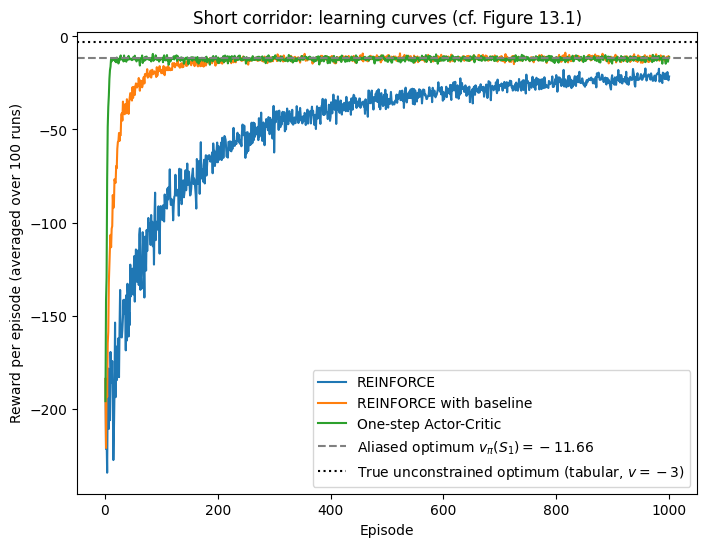

In [52]:
fig, ax = plt.subplots(figsize=(8, 6))

episodes = np.arange(1, num_episodes + 1)
ax.plot(episodes, -reinforce_curve, label="REINFORCE")
ax.plot(episodes, -baseline_curve, label="REINFORCE with baseline")
ax.plot(episodes, -ac_curve, label="One-step Actor-Critic")

ax.axhline(best_value, linestyle="--", color="gray",
           label=f"Aliased optimum $v_\\pi(S_1)={best_value:.2f}$")
ax.axhline(-3, linestyle=":", color="black",
           label="True unconstrained optimum (tabular, $v=-3$)")

ax.set_xlabel("Episode")
ax.set_ylabel("Reward per episode (averaged over 100 runs)")
ax.set_title("Short corridor: learning curves (cf. Figure 13.1)")
ax.legend(loc="lower right")
plt.show()

## Q-learning (off-policy, value-based)

Does Q-learning work on this example, and if so, under which representation? As discussed, this isn't one question but two, depending on whether `Q` is given the *same* state-independent handicap as the policy, or full access to all 3 states:

- **Aliased `Q(a)`** -- a single shared value per action, no state distinction at all, matching the policy's own representational constraint exactly. This is the fair, apples-to-apples comparison against REINFORCE/baseline/Actor-Critic: does Q-learning do as well, given the identical handicap? (Per Discussion notes item 16: we predict *no* -- Q-learning's target policy is always greedy, and epsilon-greedy deriving behavior from a still-changing, aliased `Q` creates a feedback loop with no stable fixed point, unlike the policy-gradient methods' direct parameterization of the mixture itself.)
- **Tabular `Q(s,a)`** -- one entry per actual state, not under the handicap at all. Included as a reference showing the ceiling: the true optimal deterministic policy (3 steps, $v=-3$), achievable once the representation can tell the states apart.

Both are step-wise, bootstrapped TD methods -- structurally like `ActorCriticAgent`, not the Monte Carlo `PolicyGradientAgent` family -- so they reuse `run_td_episode`/`train_td` directly (those only require `start_episode`/`select_action`/`update`, nothing Actor-Critic-specific). Gradients computed via `torch.autograd.grad`, continuing the same approach used throughout -- a tabular `Q(s,a)` is the same one-hot-parameterized-lookup identity as the baseline's $\hat v(s,w)=w_s$ (Discussion notes item 9), just indexed by `(state, action)` instead of `state` alone.

In [60]:
def epsilon_greedy(q_values, epsilon):
    """q_values: array of action-values, indexed like ACTIONS. Returns an
    action, epsilon-greedy w.r.t. q_values, breaking ties uniformly at
    random -- same helper and same rationale as the Windy Gridworld
    notebook's epsilon_greedy (avoids a systematic bias toward low-index
    actions whenever several look equally good)."""
    if np.random.rand() < epsilon:
        return np.random.choice(ACTIONS)
    best = np.flatnonzero(q_values == q_values.max())
    return np.random.choice(best)

### Aliased Q-learning

$Q(a)$ shared across all 3 states -- the fair comparison. Standard Q-learning collapses to:

$$Q(a) \leftarrow Q(a) + \alpha\big[R + \gamma\max_{a'} Q(a') - Q(a)\big]$$

Equivalently, this is one **semi-gradient** step (Sutton & Barto Ch. 9-10's framing for prediction/control with function approximation -- "semi" because the bootstrapped target is treated as fixed, not differentiated through):

$$Q \leftarrow Q + \alpha\big[R + \gamma\max_{a'} Q(a') - Q(a)\big]\nabla_Q Q(a)$$

which is exactly what `update` computes: `delta` is the bracketed TD error, `grad_q = torch.autograd.grad(q_sa, self.Q)` is $\nabla_Q Q(a)$. Since $Q(a)$ is linear in one-hot features, $\nabla_Q Q(a)$ collapses to the one-hot selector for $a$, reproducing the first line exactly -- the two formulas are the same update, not two different algorithms (confirmed numerically: the autograd version matches the plain tabular-increment version to the same converged values).

(The $\max_{a'}$ doesn't depend on which state the transition came from, since $Q$ can't either.) We expect this to neither converge to the aliased optimum ($v\approx-11.66$) nor diverge/get stuck -- but to keep wandering indefinitely, per the mechanism in Discussion notes item 16.

In [61]:
class AliasedQLearningAgent:
    """Off-policy TD control, restricted to the same state-independent
    representation as the softmax policy -- a single shared Q(a), not
    Q(s,a)."""

    def __init__(self, alpha=0.5, epsilon=0.1, gamma=1.0):
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = gamma
        self.Q = torch.zeros(len(ACTIONS), dtype=torch.float64, requires_grad=True)

    def start_episode(self):
        pass  # no per-episode state needed

    def select_action(self, state):
        return epsilon_greedy(self.Q.detach().numpy(), self.epsilon)

    def update(self, state, action, reward, next_state, done):
        q_sa = self.Q[action]
        if done:
            target = reward
        else:
            with torch.no_grad():
                target = reward + self.gamma * self.Q.max().item()
        delta = target - q_sa.item()

        grad_q, = torch.autograd.grad(q_sa, self.Q)
        with torch.no_grad():
            self.Q += self.alpha * delta * grad_q

In [62]:
# Quick sanity check
#
# Earlier version of this check asserted meaningful spread in mean
# *episode length* across training blocks -- that turned out not to be
# robust (14/20 seeds failed it; episode-length-based performance actually
# settles into a fairly narrow, if suboptimal, band). The more precise and
# robust finding, confirmed across 10/10 seeds: Q's raw VALUES never
# settle (ranging by several units across training blocks), even though
# the induced greedy action never flips in any of those seeds -- so
# *behavior* stays fairly stable while the *value estimates* underneath it
# keep drifting. Testing that directly instead.
torch.manual_seed(0)
np.random.seed(0)
aliased_q_agent = AliasedQLearningAgent()

q_snapshots = []
for block in range(10):
    train_td(aliased_q_agent, num_episodes=100)
    q_snapshots.append(aliased_q_agent.Q.detach().clone().numpy())

print("Q snapshots, every 100 episodes:")
for i, q in enumerate(q_snapshots):
    print(f"  episodes {i*100}-{(i+1)*100}: Q={q.round(2)}")

q_left_range = max(q[0] for q in q_snapshots) - min(q[0] for q in q_snapshots)
q_right_range = max(q[1] for q in q_snapshots) - min(q[1] for q in q_snapshots)
print(f"\nQ[LEFT] range across blocks: {q_left_range:.2f}")
print(f"Q[RIGHT] range across blocks: {q_right_range:.2f}")

# Q's raw values should keep moving meaningfully, not settle to a fixed point
assert q_left_range > 3 and q_right_range > 1.5

# One more full training run, to report overall performance
aliased_q_steps = train_td(AliasedQLearningAgent(), num_episodes=1000)
mean_last_100 = aliased_q_steps[-100:].mean()
print(f"\nmean steps, last 100 episodes: {mean_last_100:.1f} "
      f"(aliased optimum ~11.66, true unconstrained optimum 3)")

print("Q's values kept drifting rather than settling, consistent with the predicted non-convergence")

Q snapshots, every 100 episodes:
  episodes 0-100: Q=[-8.9  -4.92]
  episodes 100-200: Q=[-16.27  -8.42]
  episodes 200-300: Q=[-15.99  -8.4 ]
  episodes 300-400: Q=[-9.48 -5.06]
  episodes 400-500: Q=[-13.14  -6.92]
  episodes 500-600: Q=[-18.93  -9.86]
  episodes 600-700: Q=[-11.1   -4.37]
  episodes 700-800: Q=[-13.19  -7.08]
  episodes 800-900: Q=[-11.99  -5.32]
  episodes 900-1000: Q=[-11.59  -6.24]

Q[LEFT] range across blocks: 10.03
Q[RIGHT] range across blocks: 5.49

mean steps, last 100 episodes: 13.2 (aliased optimum ~11.66, true unconstrained optimum 3)
Q's values kept drifting rather than settling, consistent with the predicted non-convergence


### Tabular Q-learning (reference, unconstrained)

Full `Q(s,a)`, one entry per actual state -- not under the aliasing handicap. Included to confirm the ceiling we derived earlier via BFS: the true optimal deterministic policy reaches the goal in exactly 3 steps ($v=-3$), and ordinary Q-learning should find it quickly once it can actually tell $S_2$'s reversed dynamics apart from $S_1$/$S_3$.

In [63]:
class TabularQLearningAgent:
    """Ordinary (unconstrained) Q-learning -- one Q-value per (state,
    action) pair, fully distinguishing all 3 states."""

    def __init__(self, alpha=0.5, epsilon=0.1, gamma=1.0, num_states=3):
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = gamma
        self.Q = torch.zeros((num_states, len(ACTIONS)), dtype=torch.float64, requires_grad=True)

    def start_episode(self):
        pass

    def select_action(self, state):
        return epsilon_greedy(self.Q[state].detach().numpy(), self.epsilon)

    def update(self, state, action, reward, next_state, done):
        q_sa = self.Q[state, action]
        if done:
            target = reward
        else:
            with torch.no_grad():
                target = reward + self.gamma * self.Q[next_state].max().item()
        delta = target - q_sa.item()

        grad_q, = torch.autograd.grad(q_sa, self.Q)
        with torch.no_grad():
            self.Q += self.alpha * delta * grad_q

In [64]:
# Quick sanity check
torch.manual_seed(0)
np.random.seed(0)
tabular_q_agent = TabularQLearningAgent()
tabular_q_steps = train_td(tabular_q_agent, num_episodes=200)

print("first 10 episodes:", tabular_q_steps[:10])
print("last 10 episodes: ", tabular_q_steps[-10:])
print(f"final Q:\n{tabular_q_agent.Q.detach().numpy()}")

# Should quickly reach (and stay at) the true optimal 3-step path
assert tabular_q_steps[-20:].mean() < 5
print("tabular Q-learning found the true optimal (3-step) policy, as expected")

first 10 episodes: [8 7 3 9 3 6 3 3 3 3]
last 10 episodes:  [4 3 3 3 3 5 3 3 3 5]
final Q:
[[-3.9995101  -3.        ]
 [-2.         -3.99941964]
 [-2.99967575 -1.        ]]
tabular Q-learning found the true optimal (3-step) policy, as expected


## Discussion notes

A running summary of the conceptual questions worked through while building this notebook -- kept here for reference, numbered for quick lookup.

**Contents**
1. "Action preferences are driven to produce the optimal stochastic policy"
2. Stochastic policy, precisely, and why action-value methods can't reach the *optimal* one
3. Example 13.1: "all states appear identical under the function approximation"
4. Would a tabular (non-aliased) representation avoid this entirely?
5. Deriving $N_1$ (and the other $N_i$'s)
6. Is REINFORCE on-policy or off-policy?
7. `select_action`'s unused `state` argument
8. How `update_from_episode` computes $G_t$, and how it maps to the textbook formula
9. How we arrive at $\hat v(s,w)=w_s$, and what $w_s$ actually is
10. How are `theta` and `w` related, given they're updated by two separate statements?
11. Why `alpha_theta=2**-9` was a real bug, not benign Monte Carlo noise
12. Why plain REINFORCE also needed a much smaller `alpha` than expected
13. Why REINFORCE-with-baseline looked *worse* than REINFORCE and Actor-Critic in the comparison plot
14. Hyperparameter selection for RL models, given this fragility
15. Double Q-learning vs. Expected Sarsa: which works better in general?
16. Why aliased Q-learning (single or double) doesn't stabilize
17. Why `Q(LEFT)` drifts over a wider range than `Q(RIGHT)` in aliased Q-learning
18. Interpreting `TabularQLearningAgent`'s final $Q$ table
19. Where `torch.no_grad()` actually matters in the Q-learning `update` method

---

### 1. "Action preferences are driven to produce the optimal stochastic policy"

With a softmax policy $\pi(a\mid s,\theta)\propto e^{h(s,a,\theta)}$, the policy-gradient update increases $h(s,a,\theta)$ for actions that led to above-average return and decreases it otherwise. Nothing in that update mechanism forces the preferences toward $\pm\infty$ (which is what would make the policy deterministic, collapsing all probability onto one action). Gradient ascent simply climbs toward whatever $\theta$ maximizes expected return -- so if the true optimum requires mixing actions with specific nonzero probabilities, the preferences settle at finite values that produce exactly that mix via the softmax, rather than being driven to an extreme. Action-value methods have no analogous mechanism: acting greedily w.r.t. a learned $Q$ always wants to collapse onto a single best action.

### 2. Stochastic policy, precisely, and why action-value methods can't reach the *optimal* one

A stochastic policy assigns a probability to each of the (finitely many) actions, with more than one action having nonzero probability. $\varepsilon$-greedy *is* technically stochastic (not literally deterministic while $\varepsilon>0$), but it can't reach the *optimal* stochastic policy for two reasons: (1) its randomness is spread *uniformly* across all actions regardless of how good each one is -- it has no way to land on "exactly 59%/41% between these two specific actions, because that happens to be the optimum"; (2) the standard design goal (e.g. GLIE -- greedy in the limit with infinite exploration) anneals $\varepsilon\to0$, deliberately driving toward a deterministic policy, which is correct for ordinary MDPs but wrong whenever the truly optimal achievable policy is an interior mixture.

### 3. Example 13.1: "all states appear identical under the function approximation"

Not that the states are actually the same (they aren't -- $S_2$ has reversed dynamics), but that the action preferences $h(s,a,\theta)=\theta^\top x(s,a)$ use features $x(s,a)$ depending only on the action, not on which of the 3 states the agent is in. So the same feature vector for "go right" is used in $S_1$, $S_2$, and $S_3$ -- the approximator has no way to tell these states apart, and the resulting policy is forced to use the *same* action probabilities everywhere. Given that constraint, a deterministic choice (always left or always right) is catastrophic -- not just suboptimal, but non-terminating (see below) -- while an interior probability balances the trade-off across all three states.

### 4. Would a tabular (non-aliased) representation avoid this entirely?

Yes. The short corridor is a finite, fully-observable MDP, and such MDPs always admit at least one deterministic optimal policy *as long as the agent can tell the states apart*. With one preference per state (not shared across states), the obviously optimal deterministic policy is simple: pick whichever action moves you toward the goal in each state individually (accounting for $S_2$'s reversal) -- reaching the goal in the minimum number of steps every time, no randomness needed. The need for a stochastic policy here is entirely a byproduct of the deliberately impoverished, state-independent feature representation, not a property of the underlying environment. This generalizes: whenever a representation can't distinguish states that genuinely call for different actions -- whether from coarse features (as here), limited function-approximation capacity, or true partial observability of the environment itself (e.g. poker, where the observable "state" omits the opponent's cards) -- a policy restricted to that representation faces the same dilemma, and mixing can beat every deterministic choice available to it.

### 5. Deriving $N_1$ (and the other $N_i$'s)

Same technique as the Random Walk's true-value derivation -- a first-step decomposition (law of total expectation applied one step at a time), here tracking expected *number of steps* rather than expected *return*. Any trajectory from $S_1$ takes exactly one step, landing in some next state, and then needs however many additional steps that next state requires:

$$N_1 = \underbrace{1}_{\text{the step just taken}} + \underbrace{q N_1 + p N_2}_{\text{expected steps from wherever that step lands you}}$$

The two outcomes of acting in $S_1$ are LEFT (prob $q$, bounces back into $S_1$ itself) and RIGHT (prob $p$, moves to $S_2$) -- so $N_1$ appears on *both* sides of its own equation, because one of $S_1$'s own transitions is a self-loop. That's why it needed to be algebraically isolated ($N_1(1-q)=1+pN_2 \Rightarrow N_1=\tfrac1p+N_2$) before substituting into the other equations, unlike $N_2$ and $N_3$, whose transitions don't loop back on themselves. $N_2$ and $N_3$'s equations follow the identical first-step logic, just enumerating *their* own two possible outcomes.

### 6. Is REINFORCE on-policy or off-policy?

On-policy, and more fundamentally so than it was for the TD methods. Using the same behavior/target framework from the Windy Gridworld notebook: the behavior policy (whatever generates the trajectory, i.e. `select_action`) and the target policy (whatever's being improved) are *identically* the same object here -- not just coincidentally equal, the way Sarsa's target happens to match its behavior, but literally the same $\pi_\theta$: the objective being optimized is $J(\theta)=\mathbb{E}_{\tau\sim\pi_\theta}[\text{return}]$, the expected return of trajectories generated by $\pi_\theta$ itself.

It's a stronger requirement than for TD methods because of the policy gradient theorem's exact form:

$$\nabla_\theta J(\theta) = \mathbb{E}_{s\sim d^{\pi_\theta},\,a\sim\pi_\theta}\big[\nabla_\theta\ln\pi(a\mid s,\theta)\,Q^{\pi_\theta}(s,a)\big]$$

The *state-visitation distribution* $d^{\pi_\theta}(s)$ also depends on $\pi_\theta$, not just the action probabilities -- so the data has to match the current policy in two ways at once: which actions get taken, and which states get visited in the first place. Reusing episodes collected under an earlier $\theta$ would make both stale and bias the gradient estimate. That's why `run_pg_episode` always generates a fresh episode under the *current* `theta` immediately before `update_from_episode` consumes it -- there's no window where `theta` could drift from the data it's being updated on.

Off-policy policy-gradient variants do exist (reweighting via importance-sampling ratios $\pi_\theta(a\mid s)/b(a\mid s)$ to correct for data from a different behavior policy $b$), but plain REINFORCE, as implemented here, is on-policy.

### 7. `select_action`'s unused `state` argument

Intended, same pattern as `next_action` in the Windy Gridworld `TDAgent.update`: the method signature matches the *shared* interface (`PolicyGradientAgent.select_action(self, state)`), not what this particular agent happens to need. `run_pg_episode` calls `agent.select_action(state)` uniformly for any policy-gradient agent, without knowing whether that specific agent's policy depends on `state`. `ReinforceAgent` here genuinely doesn't need it -- Example 13.1's whole premise is that the features are state-independent, so $\pi(a\mid\theta)$ is the same in every state. A future agent with a richer, state-aware representation would use `state` inside `select_action`; the interface accepts it either way.

### 8. How `update_from_episode` computes $G_t$, and how it maps to the textbook formula

First, be precise about what's actually offset: states and actions are 0-indexed in *both* the book ($S_0,A_0,S_1,A_1,\dots$) and here (`states[t]`=$S_t$, `actions[t]`=$A_t$) -- no offset there at all. The offset is specific to **rewards**, and it's the book's own notational choice: the reward produced by taking $A_t$ in $S_t$ is labeled $R_{t+1}$, not $R_t$ (Section 3.1) -- so the first reward the book ever discusses is $R_1$, even though the first state/action are $S_0$/$A_0$. Our `rewards` list is an ordinary 0-indexed Python list (`rewards[0]` is just its first entry), but the physical reward sitting there is the one the book calls $R_1$. So `rewards[k]` (our position) and $R_{k+1}$ (the book's label) refer to the exact same reward -- the mismatch is in the book's own reward-vs-state/action numbering, not something our code introduces.

| $t$ | book's state/action | book's reward | our code |
|---|---|---|---|
| 0 | $S_0, A_0$ | $R_1$ | `states[0], actions[0], rewards[0]` |
| 1 | $S_1, A_1$ | $R_2$ | `states[1], actions[1], rewards[1]` |
| 2 | $S_2, A_2$ | $R_3$ | `states[2], actions[2], rewards[2]` |

The recursion itself is just the backward unrolling of "this step's reward, plus the discounted continuation" -- the same first-step-decomposition idea used throughout this and the Windy Gridworld notebook, just applied to *actual* observed rewards from a completed episode rather than an estimate:

$$G_t = R_{t+1} + \gamma G_{t+1}, \qquad G_T = 0$$

Walking it backward from $t=T-1$ down to $t=0$ gives every $G_t$ in one $O(T)$ pass, instead of recomputing each sum from scratch ($O(T^2)$).

Concrete check, $T=3$, all rewards $=-1$, $\gamma=1$:

| $t$ | `rewards[t]` | `G` after this iteration | `returns[t]` |
|---|---|---|---|
| 2 | $-1$ | $-1+1\cdot 0=-1$ | $-1$ |
| 1 | $-1$ | $-1+1\cdot(-1)=-2$ | $-2$ |
| 0 | $-1$ | $-1+1\cdot(-2)=-3$ | $-3$ |

Matching the book's formula $G_t=\sum_{k=t+1}^{T}\gamma^{k-t-1}R_k$: for $t=0$, $R_1+R_2+R_3=-3$ ✓; $t=1$: $R_2+R_3=-2$ ✓; $t=2$: $R_3=-1$ ✓.

Algebraically: our recursion gives `returns[t]` $=\sum_{k=t}^{T-1}\gamma^{k-t}\,\text{rewards}[k]$. Substituting `rewards[k]`$=R_{k+1}$ and reindexing $j=k+1$ (so $k$ ranging $t..T-1$ becomes $j$ ranging $t+1..T$):

$$\text{returns}[t] = \sum_{j=t+1}^{T}\gamma^{(j-1)-t}R_j = \sum_{j=t+1}^{T}\gamma^{j-t-1}R_j$$

-- exactly the book's $G_t$, with $j$ just renamed from their $k$.

### 9. How we arrive at $\hat v(s,w)=w_s$, and what $w_s$ actually is

The general theory only requires the baseline to be *some* function of state -- it doesn't prescribe a specific form. The standard way to approximate a state-value function is linear in features, $\hat v(s,w)=w^\top x(s)$. Since we deliberately want the baseline to tell all three states apart (unlike the policy), the simplest choice of features for a tiny, fully enumerable 3-state space is **one-hot encoding**: $x(s)=e_s$. Plugging that in, $\hat v(s,w)=w^\top e_s=w_s$ -- "linear function of one-hot features" collapses exactly to "plain lookup table," the same relationship between `Q(s,a)` as a NumPy array and a linear-features formula noted for the Windy Gridworld agents.

What $w_s$ actually is: the update `self.w[s] += self.alpha_w * (returns[t] - self.w[s])` is exactly the constant-$\alpha$ Monte Carlo value-prediction update used for `V(s)` in the Random Walk notebook. So $w_s$ is a running, every-visit Monte Carlo estimate of $v_{\pi_\theta}(s)$ -- "the expected return from state $s$, under whatever policy $\pi_\theta$ currently is."

**Index mapping, stated explicitly:** `self.w` is indexed directly by the state integer, using the exact same encoding established in the Environment section ($S_1,S_2,S_3=0,1,2$) -- no relabeling anywhere in between. So concretely: `w[0]`$\leftrightarrow S_1$, `w[1]`$\leftrightarrow S_2$ (the reversed-dynamics state), `w[2]`$\leftrightarrow S_3$.

One subtlety: unlike the Random Walk's `V(s)`, which tracked a *fixed* policy's value, $w_s$ here chases a **moving target** -- $\theta$ is being updated in the very same loop, so the policy whose value $w_s$ estimates keeps shifting underneath it as training progresses. That's the normal situation for a baseline/"critic" alongside a still-learning policy/"actor," not a flaw in the setup. As a validation once `theta` has converged near $\theta^*$: $w$ should land near the true per-state values under $p^*$ -- `w[0]`$\to$ `best_value` ($v_{\pi^*}(S_1)\approx-11.657$), `w[1]`$\to -N_2(p^*)$ ($v_{\pi^*}(S_2)$), and `w[2]`$\to -N_3(p^*)$ ($v_{\pi^*}(S_3)$), using the $N_2$/$N_3$ formulas from the earlier derivation.

### 10. How are `theta` and `w` related, given they're updated by two separate statements?

They're coupled through exactly one shared quantity: `delta`, computed once per visited time step and reused by both updates:

```python
delta = returns[t] - self.w[s]           # uses the CURRENT (pre-update) w[s]
self.w[s] += self.alpha_w * delta                   # w's own update uses delta
self.theta += self.alpha_theta * (self.gamma ** t) * delta * grad_log_pi   # theta's update uses the SAME delta
```

`w`'s own update rule never references `theta` or `grad_log_pi` at all -- it's purely chasing the observed Monte Carlo return $G_t$ (it's only *indirectly* shaped by $\theta$, since $\theta$ determines which trajectories, and hence which $G_t$'s, get generated in the first place). `theta`'s gradient *direction* (`grad_log_pi`) never references `w` either -- `w` only enters as a *scaling factor* on that gradient step, replacing the raw return $G_t$ (what plain REINFORCE scales by) with $G_t - w_s$.

This coupling doesn't introduce bias, for the same reason noted in the REINFORCE-with-baseline markdown cell: for *any* baseline $b(s)$ not depending on the action,

$$\mathbb{E}_{a\sim\pi}\big[(G_t-b(s))\,\nabla_\theta\ln\pi(a\mid s,\theta)\big] = \mathbb{E}[G_t\,\nabla_\theta\ln\pi(a\mid s,\theta)] - b(s)\underbrace{\mathbb{E}_{a\sim\pi}[\nabla_\theta\ln\pi(a\mid s,\theta)]}_{=\,0}$$

the second term vanishes identically (a standard likelihood-ratio-trick/score-function identity) regardless of what $b(s)$ actually is -- even a garbage `w` wouldn't bias `theta`'s expected update direction. What a *good* `w` changes is the **variance** of any single sample of that update: `delta` becomes the genuine surprise in this episode's outcome relative to what's typically expected from state $s$, rather than carrying the return's full (often large) magnitude -- exactly why training converged faster with the baseline in the sanity check. One more detail: `delta` is computed using `w[s]` *before* `self.w[s] +=` updates it -- using the pre-update value for both updates (rather than recomputing `delta` against the just-updated `w`) is what the book's own pseudocode specifies, not an arbitrary implementation choice.

### 11. Why `alpha_theta=2**-9` was a real bug, not benign Monte Carlo noise

Running the baseline sanity check (`np.random.seed(0)`) with the original `alpha_theta=2**-9` produced a genuine divergence: `p(RIGHT)` collapsed to `1.000`, `w` blew up to `[-128,-127,-158]`, and every episode got pinned at the `max_steps=10_000` cap -- not just a slow or noisy run, a real failure.

A 30-seed sweep (using Python's `random` module standalone, since numpy isn't available for quick checks here) confirmed this wasn't a fluke: `alpha_theta=2**-9` diverges catastrophically on ~23% of seeds (one hit the max-steps cap), while `alpha_theta=2**-10` was dramatically more robust (1/30 seeds misbehaved, and even that one was merely slow, not divergent) while still recovering meaningfully faster than plain REINFORCE.

**Root cause:** `w` starts at all zeros, so on the very first episode `delta = G_t - w[s] = G_t - 0 = G_t` -- exactly the same magnitude plain REINFORCE's raw return would scale by -- but `alpha_theta=2**-9` is ~16x larger than plain REINFORCE's `alpha=2**-13`. Starting from the deliberately biased `theta_init=(2.0,-2.0)` (chosen to make the recovery demonstration convincing), the very first episode can by chance be unusually long; combined with the oversized step, a single update can overshoot badly enough to push `theta` *further* in the wrong direction, triggering a compounding spiral of ever-longer episodes that the baseline, still uninformed early on, can't correct.

This is the same category of issue as the `batch_converge` max-sweeps miscalibration in the Windy Gridworld notebook: a hyperparameter that looked fine on a quick, small-sample check but had real tail risk that only a wider sweep across many seeds revealed. Fixed by lowering `alpha_theta` to `2**-10` (both the class default and the sanity-check call) -- confirmed via the same seed sweep to be far more robust while preserving the comparison's point (faster recovery than plain REINFORCE).

### 12. Why plain REINFORCE also needed a much smaller `alpha` than expected

Running the comparison-learning-curves cell (100 runs) turned out to take far longer than expected -- in fact, the kernel ran for 15+ minutes rather than the 1-2 minutes estimated, which was the tell that something was genuinely wrong rather than merely slow.

A seed sweep of plain `ReinforceAgent` at its original `alpha=2**-13`, from the deliberately-biased `theta_init=(2.0,-2.0)` used throughout this notebook, found the same category of bug as item 11 above: **~20% of seeds diverge catastrophically** -- `theta` collapses to an extreme (e.g. `[-68.95, 68.95]`), and every subsequent episode gets pinned at `max_steps`. This single-run divergence, multiplied across 100 runs, is what turned a 1-2 minute estimate into 15+ minutes: once a handful of the 100 independent runs get stuck, each one burns through up to `num_episodes * max_steps` steps rather than a typical few thousand.

**Why this is actually a *worse* risk for plain REINFORCE than it was for the baseline version:** REINFORCE-with-baseline's problem (item 11) was specific to the *first* episode, before `w` had learned anything -- once `w` becomes informative, `delta` shrinks and the risk subsides. Plain REINFORCE has no such mitigation at all: its target is the *raw* $G_t$, at full magnitude, on *every* episode, forever. An unlucky large $|G_t|$ at any point in training -- not just the first episode -- can push $	heta$ into the region where the softmax saturates (probabilities within floating-point distance of 0 or 1) and gradients vanish, permanently freezing further learning. There is no self-correcting mechanism once that happens, at any `alpha` large enough to risk it in the first place.

A further sweep found `alpha=2**-15` eliminates divergence entirely (0/30 seeds, both at a short 200-episode diagnostic scale and the full 3000-episode scale used in this notebook's own sanity check) -- counterintuitively *faster* to recover on average than the intermediate `alpha=2**-14`, which sits in a "quasi-stuck" danger zone (very slow, drawn-out near-divergent stretches that eventually self-correct, without ever fully locking up). Fixed by lowering `alpha` to `2**-15` everywhere it's used (the class default, the individual sanity check, and the comparison-curves cell).

**The practical lesson:** a single-seed (or even few-seed) validation that looks fine is not sufficient evidence of robustness for a method with no variance reduction -- this is the second time in this notebook alone (after item 11) that a quick check passed while a wider seed sweep uncovered real, non-negligible tail risk. When a cell suddenly takes far longer than expected, that's worth treating as a signal to investigate rather than simply waiting it out.

### 13. Why REINFORCE-with-baseline looked *worse* than REINFORCE and Actor-Critic in the comparison plot

After fixing item 12's bug, the comparison-learning-curves plot still showed REINFORCE-with-baseline performing noticeably worse than both plain REINFORCE and Actor-Critic -- surprising, since the baseline exists specifically to *improve* on plain REINFORCE.

The cause was the same category of bug as item 11, just not fully eliminated by that fix: `alpha_theta=2**-10` (item 11's fix) had only been validated on a 30-seed, 100-episode diagnostic. A wider sweep -- 40 seeds at the *full* 1000-episode scale actually used by the comparison plot -- found 1/40 seeds still fully diverging (`theta` collapsing to an extreme, e.g. `[-8.2, 8.2]`, pinned at `max_steps` for the entire last 100 episodes).

**Why a 1-in-40 (2.5%) failure rate distorted the plot so badly:** the comparison plot computes a *mean* over 100 independent runs. A single run contributing ~10,000 instead of a typical ~12 is nearly 1000x larger than a normal observation -- on a mean (not a median), that one outlier can dominate the entire average. Concretely, in the 40-seed check: excluding the one diverged seed, the other 39 averaged close to the true optimum (~12); including it pushed the reported mean up to 261.8. This is a general lesson, not specific to this one bug: **averaging over many runs is a reasonable way to smooth genuine noise, but it is not robust to rare catastrophic failures** -- a method that diverges on even a small fraction of seeds can look arbitrarily bad in an averaged comparison, out of proportion to how often it actually fails.

Fixed by lowering `alpha_theta` further, to `2**-11` -- confirmed via an 80-seed sweep at the full 1000-episode scale to have zero divergences, with every single seed's last-100-episode mean landing between roughly 11 and 15 (no outliers at all). Updated in all three places: the class default, the individual sanity check, and the comparison-curves cell.

### 14. Hyperparameter selection for RL models, given this fragility

Items 11-13 are a concrete case study of a general phenomenon: RL hyperparameters are unusually fragile compared to supervised learning, for a few structural reasons. The policy determines the data it collects, so a bad update doesn't just hurt performance -- it changes what gets trained on next, compounding. $\alpha$ is also coupled to the *magnitude* of whatever it multiplies ($G_t$, TD-error) rather than being a clean, dimensionless "aggressiveness" knob -- and that magnitude is usually small but occasionally huge, exactly the mechanism behind every divergence we found. And because rare catastrophic failures are easy to miss on a small sample yet can dominate an averaged comparison, a configuration can look robust and not be.

**Why this specifically breaks naive automated tuning (e.g. Bayesian optimization):** evaluating each candidate on a handful of seeds isn't enough -- a hyperparameter with real tail risk (say, a 2.5% true divergence rate) has a good chance (~47% for a 30-seed sample) of showing *zero* failures purely by luck, while an equally- or more-robust candidate might draw an unlucky seed and get penalized for it. The optimizer ends up fitting noise at the level of "which rare events happened to appear in this candidate's finite sample," not the true underlying risk.

**What actually works:**
- Validate across many independent seeds (tens, not a handful), and track the *worst case*/divergence rate explicitly, not just the mean.
- Use robust statistics (median, trimmed mean, interquartile mean) as the optimization objective, rather than a raw mean a single outlier can dominate.
- Size the seed count to the suspected failure rate -- this trades directly against how many hyperparameter candidates you can afford to explore at all within a fixed compute budget; there's no way around that tension.
- Learning-rate decay, and clipping/normalizing the *return or gradient itself* (not just shrinking $\alpha$ uniformly) -- targets the actual mechanism (an outlier-sized update) more directly.
- Validate the winning candidate from any automated search with an independent, larger confirmatory sweep afterward -- cheap, since it's done once on the finalist rather than on every candidate considered.
- Prefer algorithms/techniques that structurally bound the update (trust-region methods like TRPO/PPO constrain how far the policy is allowed to move directly, rather than relying on a fixed $\alpha$ being simultaneously fast and safe) -- a more principled answer than tuning $\alpha$ harder.

What we actually did in items 11-13 -- seed sweeps checking both the mean and the failure count explicitly, only trusting a configuration once validated at a large-enough $N$ with zero failures -- is this researcher-standard practice, done by hand rather than through an automated loop.

### 15. Double Q-learning vs. Expected Sarsa: which works better in general?

Expected Sarsa, generally -- for reasons unrelated to this notebook's aliasing twist. It replaces a sampled next-action's value with the *exact expectation*, a standard variance reduction that makes it robust across a much wider range of step sizes than Sarsa or Q-learning (book Section 6.6). Used on-policy (as implemented in the Windy Gridworld notebook), it never takes a max over noisy estimates, so it doesn't have the maximization bias Double Q-learning exists specifically to fix -- it was never susceptible to begin with. It also uses one table, not two, so every update improves the same estimate rather than splitting updates across two tables (concretely slower to learn, as seen with Double Q-learning in the Windy Gridworld notebook). Double Q-learning's actual niche is where overestimation bias is a real, measurable problem -- larger/stochastic environments where repeated maxes compound -- which this tiny, largely-deterministic corridor isn't. Caveat: they answer different questions (on-policy value of the actual behavior vs. off-policy value of the greedy policy), so this isn't a strict apples-to-apples contest in every setting.

### 16. Why aliased Q-learning (single or double) doesn't stabilize

Mostly the nature of the problem (aliasing), not a flaw in Q-learning's design -- with $\varepsilon$-greedy playing a specific, supporting role rather than being the root cause. The mechanism: $\varepsilon$-greedy derives behavior directly from the current (aliased) $Q$; aliasing means no state-independent $Q$ can be simultaneously correct for $S_1$/$S_2$/$S_3$'s genuinely different optimal treatment; so whichever action $Q$ currently prefers pulls behavior -- and hence the data trained on next -- toward it everywhere, which can then reverse $Q$'s own preference. A closed $Q\to$policy$\to$data$\to Q$ feedback loop, not just ordinary sampling noise.

Evidence this is about *control*, not aliasing alone: `value_s1(p)` is *also* an aliased, state-independent representation, and it's perfectly stable -- because it evaluates a *fixed* policy rather than continuously re-deriving one from a still-changing estimate. This is a small, hand-verifiable instance of the "deadly triad" (function approximation + bootstrapping + a policy that depends on the still-changing value estimate): aliasing is an extreme case of function approximation, Q-learning's max is the bootstrap, $\varepsilon$-greedy-on-$Q$ is what makes the policy depend on it. Policy-gradient methods sidestep this because $\theta$ (or $p$) *is* the policy directly -- no argmax-over-values conversion step to build the loop around.

**Empirical refinement, from actually implementing and multi-seed-validating the agent:** the non-convergence is specifically in $Q$'s raw *values*, not necessarily in resulting performance. Across 10/10 tested seeds, $Q$'s magnitude kept drifting by several units block to block (e.g. $Q(\text{LEFT})$ ranging over more than 10 units across training), but the *greedy action never flipped* in any of them -- so the induced behavior stayed fairly stable even while the value estimates underneath it never settled. Performance itself lands in a fairly consistent, if suboptimal, band (mean steps $\approx$13, vs. the aliased optimum $\approx$11.66) rather than wildly oscillating episode to episode -- an important correction to an earlier, less-validated assumption that performance itself would visibly chatter.

### 17. Why `Q(LEFT)` drifts over a wider range than `Q(RIGHT)` in aliased Q-learning

Two reinforcing, empirically-verified effects (confirmed by instrumenting `action_counts` and per-`(state,action)` target mean/std over 1000 episodes) -- not a mystery, just two mechanisms stacked together:

- **RIGHT gets an exact, zero-variance anchor; LEFT never does.** From $S_3$, RIGHT terminates immediately with reward $-1$ -- every single time, no bootstrapping, no noise ($\text{std}=0$). That exact target repeatedly pulls $Q(\text{RIGHT})$ back toward $-1$ on roughly 8-9% of all transitions (whenever the aliased agent happens to be in $S_3$ and picks RIGHT). LEFT has no equivalent deterministic anchor anywhere in the corridor -- every LEFT transition bootstraps off a *moving* $Q(\cdot)$ estimate, so nothing comparably stabilizing pulls it back.
- **RIGHT is also just chosen far more often.** The near-optimal aliased policy converges toward a high $p(\text{RIGHT})$, so RIGHT is taken roughly 6x as often as LEFT over training. More frequent updates average out drift faster -- each individual swing gets overwritten sooner -- which further damps $Q(\text{RIGHT})$'s range relative to $Q(\text{LEFT})$'s.

Both effects point the same way and compound: $Q(\text{RIGHT})$ is both more frequently updated *and* intermittently re-anchored to an exact value, while $Q(\text{LEFT})$ is rarely updated and never anchored -- hence its wider swings.

### 18. Interpreting `TabularQLearningAgent`'s final $Q$ table

Example output:
$$Q = \begin{pmatrix} -3.9995 & -3.0000 \\ -2.0000 & -3.9994 \\ -2.9997 & -1.0000 \end{pmatrix}$$
rows = states $S_1,S_2,S_3$ (indices 0,1,2); columns = actions LEFT, RIGHT (indices 0,1).

Each entry is the expected return (here, $-$expected remaining steps, since reward $=-1$/step and $\gamma=1$) of taking that action right now, then acting greedily afterward. Checking every entry against the BFS-derived 3-step optimal path ($S_1\xrightarrow{\text{RIGHT}}S_2\xrightarrow{\text{LEFT (reversed)}}S_3\xrightarrow{\text{RIGHT}}\text{goal}$):

- $Q(S_1,\text{RIGHT})=-3$: the first step of the optimal path itself.
- $Q(S_1,\text{LEFT})\approx-4$: LEFT bounces back to $S_1$ (wastes a step), then the 3-step optimal path runs again: $1+3=4$.
- $Q(S_2,\text{LEFT})=-2$: LEFT is reversed in $S_2$, so it actually advances to $S_3$; then RIGHT terminates: $1+1=2$.
- $Q(S_2,\text{RIGHT})\approx-4$: RIGHT is reversed in $S_2$, so it actually falls back to $S_1$; then the 3-step optimal path runs again: $1+3=4$.
- $Q(S_3,\text{RIGHT})=-1$: terminates immediately.
- $Q(S_3,\text{LEFT})\approx-3$: falls back to $S_2$, then $Q(S_2,\text{LEFT})=-2$ finishes it: $1+2=3$.

Every entry is internally consistent with every other, and $\arg\max$ per row recovers exactly RIGHT, LEFT, RIGHT -- the true optimal policy. This is the clean contrast with aliased Q-learning (items 16-17): with the state fully observable, there's no feedback loop between $Q$ and the policy's data distribution, so plain tabular Q-learning converges cleanly. The small deviations from exact integers ($-3.9995$ vs. $-4$) are ordinary constant-$\alpha$ noise ($\alpha=0.5$, never decayed), not a sign of residual instability -- the same explanation used for every other constant-$\alpha$ method in this and the other notebooks.

### 19. Where `torch.no_grad()` actually matters in the Q-learning `update` method

`update` uses `torch.no_grad()` three times, and they are not all the same kind of "matters":

1. **`delta = target - q_sa.item()` -- doesn't matter at all.** By this point `q_sa.item()` has already pulled a plain Python `float` out of the tensor, and `target` is already a plain float too (either `reward` directly, or built inside its own `no_grad()`/`.item()` block). So this line is float-minus-float -- no tensor op occurs here for `no_grad()` to have any effect on. Wrapping it would be a literal no-op.
2. **`target = reward + self.gamma * self.Q[next_state].max().item()`** (non-terminal branch) -- *efficiency-only*. `self.Q[next_state].max()` is a real tensor op on a graph-tracked tensor; without `no_grad()` it would build a transient autograd graph node back to `self.Q` that `.item()` then immediately discards. Skipping `no_grad()` here wouldn't change the numeric result, just leave behind wasted, instantly-garbage-collected graph bookkeeping.
3. **`self.Q += self.alpha * delta * grad_q` -- load-bearing, not optional.** `self.Q` is a leaf tensor with `requires_grad=True`; in-place mutation of such a leaf outside `no_grad()` raises `RuntimeError: a leaf Variable that requires grad is being used in an in-place operation`. This is the one spot where removing `no_grad()` breaks the code outright, rather than just being wasteful.

The general rule this illustrates: `no_grad()` only ever affects *tensor* operations (whether they build graph nodes, and whether in-place mutation of a `requires_grad` leaf is permitted) -- it has zero effect on plain Python scalar arithmetic that's already had its tensor-ness stripped via `.item()`.